

```
# This is formatted as code
```

# Simulation-Based Analysis and Optimization of Toll Booth Queues at the Padma Bridge Toll Plaza

**Course:** CSE 413 – Simulation and Modeling Lab
**Method:** Discrete-event queue simulation (M/M/c) + Monte Carlo replication + statistical validation

---

### What this notebook does
Vehicles arrive at the toll plaza at random times and each takes a random amount of time to pay.
If every open booth is busy, the vehicle waits in a single queue. We build this system in Python and run it
hundreds of times (Monte Carlo) to answer one practical question:

> **How many toll booths should be open on a normal day and during Eid so that vehicles do not wait too long?**

### Steps
1. Set the model parameters (arrival rate, service time, booths)
2. Generate random arrivals and **validate** them (KS test, Chi-square test)
3. Build the queue simulation
4. Run Monte Carlo replications for every booth count
5. **Validate** the simulation against queueing theory (Erlang-C formula, one-sample t-test)
6. Compare booth configurations (normality test, two-sample t-test, 95% CI)
7. Cost-based optimization of the number of booths
8. Visualisation and animation
9. Conclusion

## 1. Import libraries

In [ ]:
import heapq
import math
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
SEED = 42          # fixed seed -> the same results every time the notebook is run
rng = np.random.default_rng(SEED)

## 2. Model parameters

All values are **assumptions** chosen to represent one direction of the toll plaza during a busy period.
They can be changed in this cell and the whole notebook re-run.

| Symbol | Meaning | Normal day | Eid rush |
|---|---|---|---|
| $\lambda$ | vehicles arriving per minute | 5 | 10 |
| $1/\mu$ | average time to pay toll (minutes) | 0.5 (30 s) | 0.5 (30 s) |
| $c$ | number of open booths | 3 – 7 | 6 – 10 |

- Inter-arrival times are **exponential** (arrivals form a Poisson process).
- Service times are **exponential** with mean 30 seconds.
- One common queue, first-come-first-served (FCFS).
- Each replication simulates **180 minutes**; the first **30 minutes** are discarded as warm-up so the system starts from a realistic, non-empty state.

In [ ]:
SCENARIOS = {
    "Normal day": {"lam": 5.0,  "booths": [3, 4, 5, 6, 7]},
    "Eid rush":   {"lam": 10.0, "booths": [6, 7, 8, 9, 10]},
}
MEAN_SERVICE = 0.5     # minutes per vehicle  (mu = 2 vehicles/min per booth)
MU = 1 / MEAN_SERVICE
SIM_TIME = 180         # minutes simulated per replication
WARM_UP = 30           # minutes discarded at the start
REPLICATIONS = 300     # Monte Carlo runs per configuration
TARGET_WAIT = 10/60    # service-level target: average wait <= 10 seconds
ALPHA = 0.05           # significance level for all tests

for name, s in SCENARIOS.items():
    print(f"{name}: lambda = {s['lam']} veh/min, booths tested = {s['booths']}")
print(f"Service rate per booth mu = {MU} veh/min")

Normal day: lambda = 5.0 veh/min, booths tested = [3, 4, 5, 6, 7]
Eid rush: lambda = 10.0 veh/min, booths tested = [6, 7, 8, 9, 10]
Service rate per booth mu = 2.0 veh/min


## 3. Random arrival generation and validation

Before trusting the simulation we check that the random numbers really follow the distributions we assumed.

**Inter-arrival time** (exponential):
$$f(t) = \lambda e^{-\lambda t}, \qquad t \ge 0$$

**Arrivals per minute** (Poisson):
$$P(N = k) = \frac{\lambda^{k} e^{-\lambda}}{k!}$$

Two tests are used:
- **Kolmogorov–Smirnov (KS) test** — are the inter-arrival times exponential?
- **Chi-square goodness-of-fit test** — do the counts per minute follow a Poisson distribution?

$H_0$: the data follow the assumed distribution. If $p > 0.05$ we **fail to reject** $H_0$ (the generator is acceptable).

In [ ]:
lam = SCENARIOS["Normal day"]["lam"]
inter = rng.exponential(1 / lam, size=5000)          # 5000 inter-arrival times
arrivals = np.cumsum(inter)

# --- KS test: inter-arrival times vs Exponential(scale = 1/lambda)
ks_stat, ks_p = stats.kstest(inter, "expon", args=(0, 1 / lam))
print("KS test (inter-arrival ~ Exponential)")
print(f"  D = {ks_stat:.4f}, p-value = {ks_p:.4f} ->",
      "Fail to reject H0 (exponential)" if ks_p > ALPHA else "Reject H0")

# --- Chi-square test: arrivals per minute vs Poisson(lambda)
minutes = int(arrivals[-1])
counts = np.bincount(arrivals[arrivals < minutes].astype(int), minlength=minutes)
k_max = 10                                            # group k >= 10 into one bin
obs = np.array([np.sum(counts == k) for k in range(k_max)] + [np.sum(counts >= k_max)])
probs = np.array([stats.poisson.pmf(k, lam) for k in range(k_max)] + [stats.poisson.sf(k_max - 1, lam)])
exp_ = probs * obs.sum()
# merge low-expected bins at the left so every expected count >= 5
while exp_[0] < 5:
    exp_[1] += exp_[0]; obs[1] += obs[0]; exp_, obs = exp_[1:], obs[1:]
chi_stat, chi_p = stats.chisquare(obs, exp_ * obs.sum() / exp_.sum(), ddof=1)
print("\nChi-square test (arrivals per minute ~ Poisson)")
print(f"  chi2 = {chi_stat:.3f}, p-value = {chi_p:.4f} ->",
      "Fail to reject H0 (Poisson)" if chi_p > ALPHA else "Reject H0")
print(f"\nSample mean arrivals/min = {counts.mean():.3f} (expected {lam})")

KS test (inter-arrival ~ Exponential)
  D = 0.0125, p-value = 0.4075 -> Fail to reject H0 (exponential)

Chi-square test (arrivals per minute ~ Poisson)
  chi2 = 11.442, p-value = 0.2466 -> Fail to reject H0 (Poisson)

Sample mean arrivals/min = 5.080 (expected 5.0)


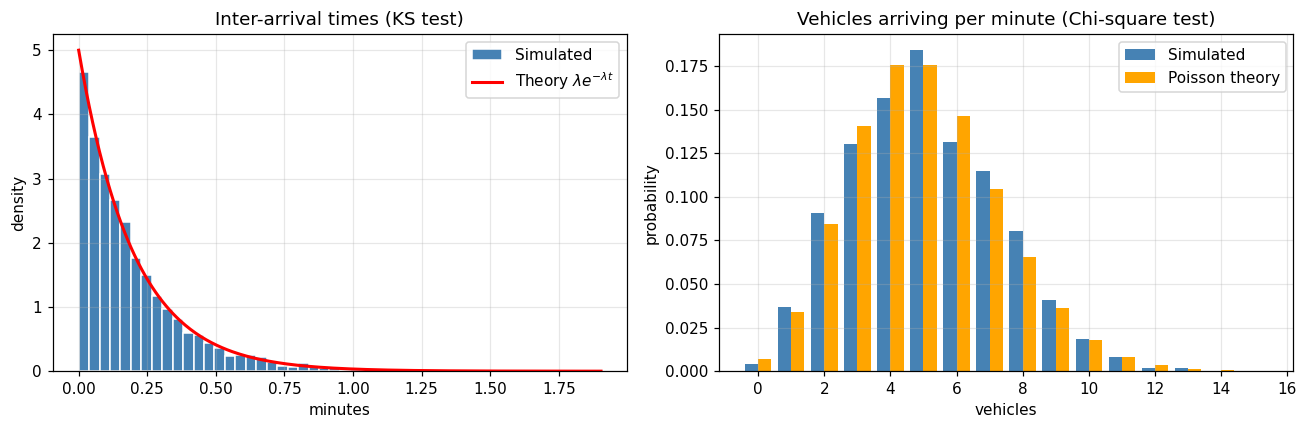

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(inter, bins=50, density=True, color="steelblue", edgecolor="white", label="Simulated")
t = np.linspace(0, inter.max(), 300)
ax[0].plot(t, lam * np.exp(-lam * t), "r-", lw=2, label=r"Theory $\lambda e^{-\lambda t}$")
ax[0].set(title="Inter-arrival times (KS test)", xlabel="minutes", ylabel="density"); ax[0].legend()

k = np.arange(0, 16)
ax[1].bar(k - 0.2, [np.mean(counts == i) for i in k], width=0.4, label="Simulated", color="steelblue")
ax[1].bar(k + 0.2, stats.poisson.pmf(k, lam), width=0.4, label="Poisson theory", color="orange")
ax[1].set(title="Vehicles arriving per minute (Chi-square test)", xlabel="vehicles", ylabel="probability")
ax[1].legend(); plt.tight_layout(); plt.show()

## 4. The queue simulation (core model)

For each vehicle $n$:

$$A_n = A_{n-1} + X_n \qquad \text{(arrival time, } X_n \sim \text{Exp}(\lambda))$$
$$S_n = \max\big(A_n,\; F_{\min}\big) \qquad \text{(service start, } F_{\min} = \text{earliest free booth)}$$
$$D_n = S_n + Y_n \qquad \text{(departure, } Y_n \sim \text{Exp}(\mu))$$
$$W_n = S_n - A_n \qquad \text{(waiting time in queue)}$$

The earliest-free booth is tracked with a **min-heap**, so each vehicle goes to whichever booth becomes free first.

In [ ]:
def simulate_toll(lam, c, rng, sim_time=SIM_TIME, warm_up=WARM_UP, mean_service=MEAN_SERVICE):
    # 1) arrival times (Poisson process)
    n_est = int(lam * sim_time * 1.3) + 50
    arr = np.cumsum(rng.exponential(1 / lam, size=n_est))
    arr = arr[arr < sim_time]
    # 2) service times
    service = rng.exponential(mean_service, size=len(arr))
    # 3) FCFS multi-server queue using a heap of booth free-times
    booths = [0.0] * c
    heapq.heapify(booths)
    start = np.empty(len(arr))
    for i, (a, s) in enumerate(zip(arr, service)):
        free = heapq.heappop(booths)
        start[i] = max(a, free)
        heapq.heappush(booths, start[i] + s)
    wait = start - arr
    keep = arr >= warm_up                     # discard warm-up period
    return {"arrival": arr, "start": start, "depart": start + service, "wait": wait,
            "wait_ss": wait[keep], "n": int(keep.sum())}

# quick single run
demo = simulate_toll(5.0, 4, rng)
print(f"One run, normal day, 4 booths: {demo['n']} vehicles served after warm-up")
print(f"  average wait = {demo['wait_ss'].mean()*60:.1f} s, max wait = {demo['wait_ss'].max()*60:.1f} s")

One run, normal day, 4 booths: 771 vehicles served after warm-up
  average wait = 5.2 s, max wait = 84.5 s


## 5. Monte Carlo replications

One run is affected by luck. We repeat each configuration **300 times** with fresh random numbers and record the
average waiting time of each run. The mean of these 300 averages is the Monte Carlo estimate:

$$\bar{W}_q = \frac{1}{R}\sum_{r=1}^{R} W_q^{(r)}, \qquad R = 300$$

In [ ]:
results = {}
for name, s in SCENARIOS.items():
    results[name] = {}
    for c in s["booths"]:
        reps = np.array([simulate_toll(s["lam"], c, rng)["wait_ss"].mean() for _ in range(REPLICATIONS)])
        results[name][c] = reps
    print(f"{name}: done")

Normal day: done
Eid rush: done


## 6. Validation against queueing theory (Erlang-C)

For an M/M/c queue the exact average waiting time is known. With utilisation $\rho = \dfrac{\lambda}{c\mu}$:

$$P_{wait} = \frac{\dfrac{(c\rho)^c}{c!}\cdot\dfrac{1}{1-\rho}}{\displaystyle\sum_{k=0}^{c-1}\frac{(c\rho)^k}{k!} + \dfrac{(c\rho)^c}{c!}\cdot\dfrac{1}{1-\rho}}
\qquad\qquad
W_q = \frac{P_{wait}}{c\mu - \lambda}$$

If our simulation is correct, its average should match $W_q$. We test this with a **one-sample t-test**:
$H_0$: simulated mean $= W_q$ (theory). Failing to reject $H_0$ means the model is **validated**.

In [ ]:
def erlang_c_wq(lam, mu, c):
    rho = lam / (c * mu)
    if rho >= 1:
        return np.inf, rho, 1.0
    a = lam / mu
    top = (a ** c / math.factorial(c)) / (1 - rho)
    p_wait = top / (sum(a ** k / math.factorial(k) for k in range(c)) + top)
    return p_wait / (c * mu - lam), rho, p_wait

print(f"{'Scenario':<12}{'c':>3}{'rho':>7}{'Sim Wq (s)':>12}{'Theory Wq (s)':>15}{'t':>8}{'p-value':>9}  Result")
summary = []
for name, s in SCENARIOS.items():
    for c in s["booths"]:
        sim = results[name][c]
        wq, rho, pw = erlang_c_wq(s["lam"], MU, c)
        t_stat, p_val = stats.ttest_1samp(sim, wq)
        verdict = "validated" if p_val > ALPHA else "differs"
        summary.append((name, c, rho, sim.mean(), wq, sim.std(ddof=1), p_val))
        print(f"{name:<12}{c:>3}{rho:>7.3f}{sim.mean()*60:>12.2f}{wq*60:>15.2f}{t_stat:>8.2f}{p_val:>9.3f}  {verdict}")

Scenario      c    rho  Sim Wq (s)  Theory Wq (s)       t  p-value  Result
Normal day    3  0.833       41.55          42.13   -0.50    0.618  validated
Normal day    4  0.625        6.28           6.40   -0.85    0.398  validated
Normal day    5  0.500        1.53           1.56   -0.84    0.402  validated
Normal day    6  0.417        0.45           0.41    2.36    0.019  differs
Normal day    7  0.357        0.10           0.10   -0.76    0.445  validated
Eid rush      6  0.833       17.55          17.63   -0.17    0.865  validated
Eid rush      7  0.714        4.85           4.86   -0.12    0.903  validated
Eid rush      8  0.625        1.71           1.67    1.02    0.306  validated
Eid rush      9  0.556        0.61           0.60    0.29    0.773  validated
Eid rush     10  0.500        0.22           0.22    0.10    0.917  validated


> **Note:** ten separate t-tests are run at $\alpha = 0.05$, so roughly one "differs" result can appear purely
> by chance (multiple-testing effect), especially where waiting times are a fraction of a second. The relative
> error below shows how close simulation and theory are in practical terms.

In [ ]:
for name, c, rho, sm, wq, sd, p in summary:
    print(f"{name:<12} c={c:<3} relative error = {100*(sm-wq)/wq:+6.2f}%")

Normal day   c=3   relative error =  -1.39%
Normal day   c=4   relative error =  -1.91%
Normal day   c=5   relative error =  -2.32%
Normal day   c=6   relative error =  +9.49%
Normal day   c=7   relative error =  -4.59%
Eid rush     c=6   relative error =  -0.41%
Eid rush     c=7   relative error =  -0.28%
Eid rush     c=8   relative error =  +2.29%
Eid rush     c=9   relative error =  +0.85%
Eid rush     c=10  relative error =  +0.43%


## 7. Comparing booth configurations

### 7.1 Normality check
The t-test assumes the replication means are roughly normal. By the **Central Limit Theorem** averages of many
vehicles should be close to normal; we check with D'Agostino's normality test.

In [ ]:
for name, s in SCENARIOS.items():
    for c in s["booths"]:
        stat, p = stats.normaltest(results[name][c])
        print(f"{name:<12} c={c}: p = {p:.3f}", "(normal)" if p > ALPHA else "(not normal - large sample, t-test still robust)")

Normal day   c=3: p = 0.000 (not normal - large sample, t-test still robust)
Normal day   c=4: p = 0.000 (not normal - large sample, t-test still robust)
Normal day   c=5: p = 0.000 (not normal - large sample, t-test still robust)
Normal day   c=6: p = 0.000 (not normal - large sample, t-test still robust)
Normal day   c=7: p = 0.000 (not normal - large sample, t-test still robust)
Eid rush     c=6: p = 0.000 (not normal - large sample, t-test still robust)
Eid rush     c=7: p = 0.000 (not normal - large sample, t-test still robust)
Eid rush     c=8: p = 0.000 (not normal - large sample, t-test still robust)
Eid rush     c=9: p = 0.000 (not normal - large sample, t-test still robust)
Eid rush     c=10: p = 0.000 (not normal - large sample, t-test still robust)


### 7.2 Two-sample t-test: does adding one more booth make a real difference?

For each scenario we compare the **smallest stable** booth count with one extra booth.
Because the two groups have different variances we use **Welch's t-test**:

$$t = \frac{\bar{x}_1 - \bar{x}_2}{\sqrt{\dfrac{s_1^2}{n_1} + \dfrac{s_2^2}{n_2}}}$$

$H_0$: $\mu_1 = \mu_2$ (adding a booth does not change the average wait).

In [ ]:
def compare(name, c1, c2):
    x1, x2 = results[name][c1], results[name][c2]
    t_stat, p_val = stats.ttest_ind(x1, x2, equal_var=False)
    diff = x1.mean() - x2.mean()
    se = np.sqrt(x1.var(ddof=1) / len(x1) + x2.var(ddof=1) / len(x2))
    dfw = se**4 / ((x1.var(ddof=1)/len(x1))**2/(len(x1)-1) + (x2.var(ddof=1)/len(x2))**2/(len(x2)-1))
    ci = stats.t.interval(0.95, dfw, loc=diff, scale=se)
    print(f"{name}: {c1} booths vs {c2} booths")
    print(f"  mean wait: {x1.mean()*60:.2f} s  vs  {x2.mean()*60:.2f} s")
    print(f"  t = {t_stat:.2f}, df = {dfw:.1f}, p = {p_val:.2e}")
    print(f"  95% CI of the difference: [{ci[0]*60:.2f}, {ci[1]*60:.2f}] seconds")
    print("  Decision:", "Reject H0 - the extra booth significantly reduces waiting.\n" if p_val < ALPHA
          else "Fail to reject H0 - no significant difference.\n")

compare("Normal day", 3, 4)
compare("Normal day", 4, 5)
compare("Eid rush", 6, 7)
compare("Eid rush", 7, 8)

Normal day: 3 booths vs 4 booths
  mean wait: 41.55 s  vs  6.28 s
  t = 29.83, df = 308.0, p = 7.45e-93
  95% CI of the difference: [32.95, 37.60] seconds
  Decision: Reject H0 - the extra booth significantly reduces waiting.

Normal day: 4 booths vs 5 booths
  mean wait: 6.28 s  vs  1.53 s
  t = 31.57, df = 352.5, p = 8.74e-105
  95% CI of the difference: [4.45, 5.04] seconds
  Decision: Reject H0 - the extra booth significantly reduces waiting.

Eid rush: 6 booths vs 7 booths
  mean wait: 17.55 s  vs  4.85 s
  t = 28.50, df = 340.3, p = 3.52e-92
  95% CI of the difference: [11.83, 13.58] seconds
  Decision: Reject H0 - the extra booth significantly reduces waiting.

Eid rush: 7 booths vs 8 booths
  mean wait: 4.85 s  vs  1.71 s
  t = 26.24, df = 363.0, p = 7.38e-86
  95% CI of the difference: [2.90, 3.37] seconds
  Decision: Reject H0 - the extra booth significantly reduces waiting.



## 8. Cost-based optimization

More booths reduce waiting but cost money. We pick the booth count that minimises total hourly cost:

$$TC(c) = c \cdot C_b \;+\; \lambda \cdot 60 \cdot W_q(c) \cdot C_w$$

- $C_b$ = cost of operating one booth for one hour (staff + overhead) — assumed **Tk 600/hour**
- $C_w$ = cost of one vehicle waiting one minute (fuel + time of passengers) — assumed **Tk 10/minute**

Normal day: cost-optimal booths = 4  (total = Tk 2,714/hour)
Eid rush: cost-optimal booths = 7  (total = Tk 4,685/hour)


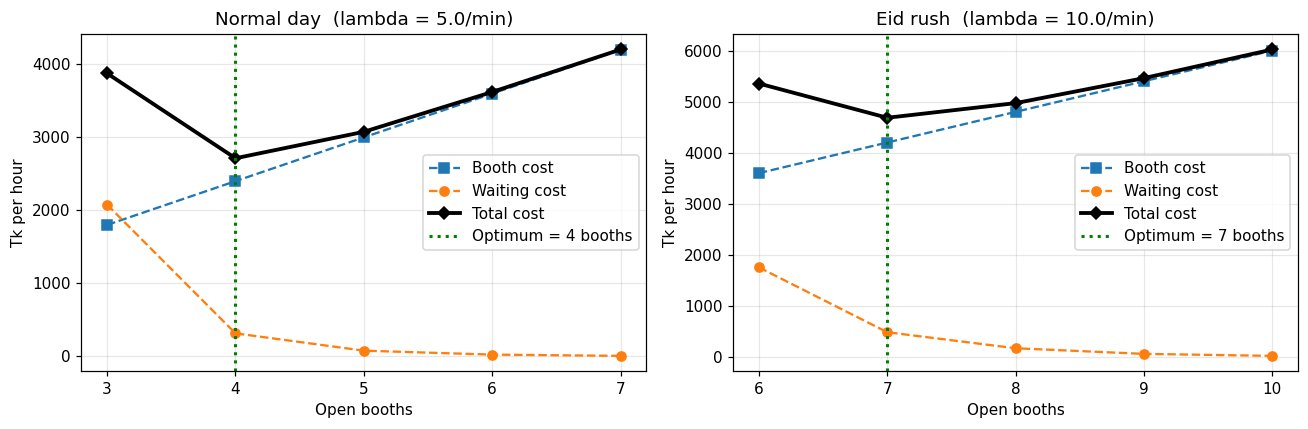

In [ ]:
C_BOOTH, C_WAIT = 600, 10
best = {}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, (name, s) in enumerate(SCENARIOS.items()):
    cs = s["booths"]
    wq = np.array([results[name][c].mean() for c in cs])
    booth_cost = np.array(cs) * C_BOOTH
    wait_cost = s["lam"] * 60 * wq * C_WAIT
    total = booth_cost + wait_cost
    best[name] = cs[int(np.argmin(total))]
    ax[i].plot(cs, booth_cost, "s--", label="Booth cost")
    ax[i].plot(cs, wait_cost, "o--", label="Waiting cost")
    ax[i].plot(cs, total, "D-", lw=2.5, color="black", label="Total cost")
    ax[i].axvline(best[name], color="green", ls=":", lw=2, label=f"Optimum = {best[name]} booths")
    ax[i].set(title=f"{name}  (lambda = {s['lam']}/min)", xlabel="Open booths", ylabel="Tk per hour")
    ax[i].set_xticks(cs); ax[i].legend()
    print(f"{name}: cost-optimal booths = {best[name]}  (total = Tk {total.min():,.0f}/hour)")
plt.tight_layout(); plt.show()

## 9. Visualisation

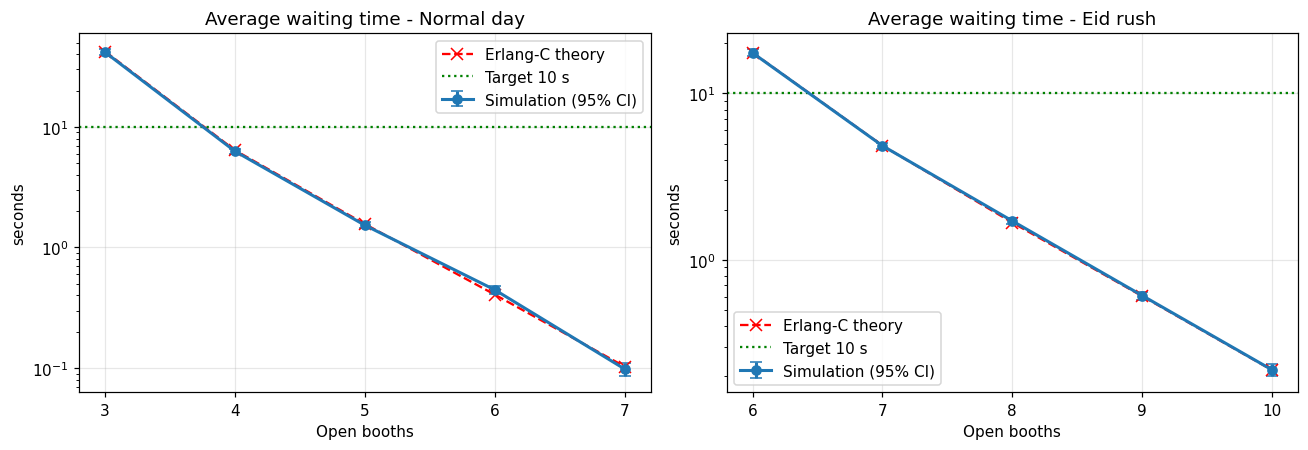

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for i, (name, s) in enumerate(SCENARIOS.items()):
    cs = s["booths"]
    sim = np.array([results[name][c].mean() * 60 for c in cs])
    err = np.array([1.96 * results[name][c].std(ddof=1) / np.sqrt(REPLICATIONS) * 60 for c in cs])
    th = np.array([erlang_c_wq(s["lam"], MU, c)[0] * 60 for c in cs])
    ax[i].errorbar(cs, sim, yerr=err, fmt="o-", capsize=4, lw=2, label="Simulation (95% CI)")
    ax[i].plot(cs, th, "r--x", ms=8, label="Erlang-C theory")
    ax[i].axhline(TARGET_WAIT * 60, color="green", ls=":", label=f"Target {TARGET_WAIT*60:.0f} s")
    ax[i].set(title=f"Average waiting time - {name}", xlabel="Open booths", ylabel="seconds")
    ax[i].set_xticks(cs); ax[i].set_yscale("log"); ax[i].legend()
plt.tight_layout(); plt.show()

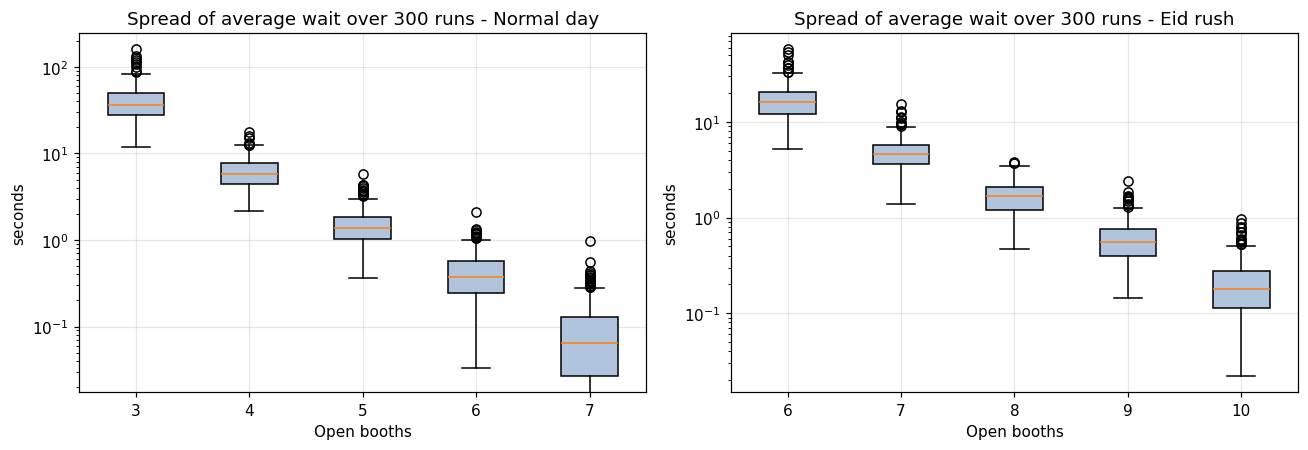

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for i, (name, s) in enumerate(SCENARIOS.items()):
    data = [results[name][c] * 60 for c in s["booths"]]
    ax[i].boxplot(data, tick_labels=[str(c) for c in s["booths"]], patch_artist=True,
                  boxprops=dict(facecolor="lightsteelblue"))
    ax[i].set(title=f"Spread of average wait over {REPLICATIONS} runs - {name}",
              xlabel="Open booths", ylabel="seconds"); ax[i].set_yscale("log")
plt.tight_layout(); plt.show()

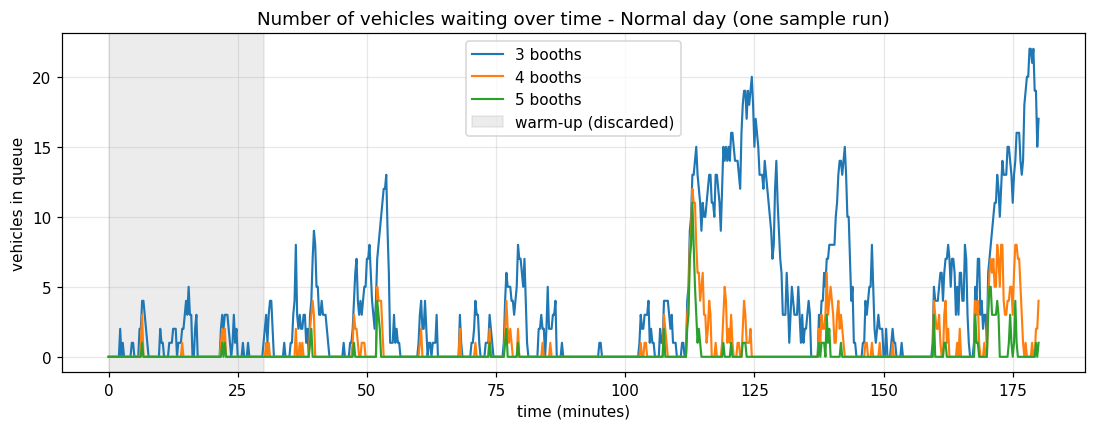

In [ ]:
def queue_length(run, grid):
    a, st = np.sort(run["arrival"]), np.sort(run["start"])
    return np.searchsorted(a, grid, side="right") - np.searchsorted(st, grid, side="right")

grid = np.linspace(0, SIM_TIME, 721)
plt.figure(figsize=(12, 4))
for c in [3, 4, 5]:
    run = simulate_toll(5.0, c, np.random.default_rng(7))
    plt.plot(grid, queue_length(run, grid), lw=1.4, label=f"{c} booths")
plt.axvspan(0, WARM_UP, color="grey", alpha=0.15, label="warm-up (discarded)")
plt.title("Number of vehicles waiting over time - Normal day (one sample run)")
plt.xlabel("time (minutes)"); plt.ylabel("vehicles in queue"); plt.legend(); plt.show()

### 9.1 Animation — queue at the toll plaza
Left: 3 booths, right: 5 booths, on a normal day (same arriving vehicles, same random seed for arrivals).
Each frame is one minute of simulated time.

In [ ]:
def run_with_seed(c, seed):
    return simulate_toll(5.0, c, np.random.default_rng(seed))

runs = {3: run_with_seed(3, 11), 5: run_with_seed(5, 11)}
frames = np.arange(30, 150, 1.0)          # minutes 30-150
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

def draw(t):
    for ax, (c, run) in zip(axes, runs.items()):
        ax.clear()
        q = int(queue_length(run, np.array([t]))[0])
        busy = int(np.sum((run["start"] <= t) & (run["depart"] > t)))   # booths serving a vehicle
        for b in range(c):
            ax.add_patch(plt.Rectangle((8.5, b * 1.2), 1, 0.9,
                         color="tomato" if b < busy else "lightgreen"))
        for j in range(min(q, 40)):
            ax.add_patch(plt.Rectangle((7.6 - (j % 20) * 0.38, (j // 20) * 0.7 + 0.2), 0.3, 0.45, color="royalblue"))
        ax.set_xlim(0, 10); ax.set_ylim(-0.5, max(6.5, c * 1.2 + 0.5)); ax.axis("off")
        ax.set_title(f"{c} booths | minute {t:.0f} | waiting: {q}")
    return []

fig.suptitle("red = busy booth   |   green = free booth   |   blue = vehicle waiting in queue", fontsize=10)
ani = animation.FuncAnimation(fig, draw, frames=frames, interval=150)
plt.close(fig)
HTML(ani.to_jshtml())

## 10. Conclusion (generated from the results above)

In [ ]:
print("=" * 70)
for name, s in SCENARIOS.items():
    cs = s["booths"]
    meets = [c for c in cs if results[name][c].mean() <= TARGET_WAIT]
    min_ok = meets[0] if meets else None
    print(f"{name} (lambda = {s['lam']} vehicles/min)")
    for c in cs:
        print(f"   {c} booths -> average wait {results[name][c].mean()*60:7.1f} s")
    print(f"   Minimum booths meeting the {TARGET_WAIT*60:.0f}-second target : {min_ok}")
    print(f"   Cost-optimal number of booths              : {best[name]}")
    print("-" * 70)
print("Random input validated by KS and Chi-square tests;")
print("simulation validated against Erlang-C theory; booth differences tested with Welch t-tests.")

Normal day (lambda = 5.0 vehicles/min)
   3 booths -> average wait    41.5 s
   4 booths -> average wait     6.3 s
   5 booths -> average wait     1.5 s
   6 booths -> average wait     0.4 s
   7 booths -> average wait     0.1 s
   Minimum booths meeting the 10-second target : 4
   Cost-optimal number of booths              : 4
----------------------------------------------------------------------
Eid rush (lambda = 10.0 vehicles/min)
   6 booths -> average wait    17.6 s
   7 booths -> average wait     4.8 s
   8 booths -> average wait     1.7 s
   9 booths -> average wait     0.6 s
   10 booths -> average wait     0.2 s
   Minimum booths meeting the 10-second target : 7
   Cost-optimal number of booths              : 7
----------------------------------------------------------------------
Random input validated by KS and Chi-square tests;
simulation validated against Erlang-C theory; booth differences tested with Welch t-tests.
